<a href="https://colab.research.google.com/github/pg3915/Tugas-Tik/blob/main/Jejak_Api_Analisis_Anggaran_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Jejak Api Nusantara
## Analisis anggaran kebakaran lahan dengan Python
1.000 kejadian simulasi di Indonesia, 2016–2025. Jalankan setiap cell kode dari atas ke bawah dengan **Shift + Enter**. Pada langkah unggah, pilih database SQLite versi anggaran. Tabel dan grafik muncul di bawah cell masing-masing. Pada sesi Colab baru, unggah kembali database.

### 1. Sumber, definisi, dan pemeriksaan data
Analisis memakai view `analisis_anggaran`: tepat satu baris per kejadian. Tabel pihak memiliki relasi banyak pihak per kejadian sehingga tidak digabung langsung ke tabel keuangan. Operasi udara sudah termasuk biaya pemadaman. Kejadian dikelompokkan menurut tahun mulai, bukan tahun pembayaran.

**Impor pustaka**

**Cell 1**

In [9]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

**Unggah database SQLite**

**Cell 2**

In [10]:
from google.colab import files
from pathlib import Path

print("Pilih file Jejak_Api_Anggaran_1000_Dummy.sqlite dari laptop.")
unggahan = files.upload()
if len(unggahan) != 1:
    raise ValueError("Jalankan ulang cell ini dan pilih satu file database.")
nama_file, isi = next(iter(unggahan.items()))
if not isi.startswith(b"SQLite format 3\x00"):
    raise ValueError("Pilih database SQLite dari proyek Jejak Api.")
DB = Path(nama_file)
DB.write_bytes(isi)
print("Database siap:", DB.name)

Pilih file Jejak_Api_Anggaran_1000_Dummy.sqlite dari laptop.


Saving Jejak_Api_Anggaran_1000_Dummy(2)(1).sqlite to Jejak_Api_Anggaran_1000_Dummy(2)(1).sqlite
Database siap: Jejak_Api_Anggaran_1000_Dummy(2)(1).sqlite


**Siapkan folder hasil dan fungsi tampilan**

**Cell 3**

In [11]:
HASIL=Path("hasil"); HASIL.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize":(11,5),"font.size":10,"axes.spines.top":False,"axes.spines.right":False})
WARNA=["#357c85","#d95838","#e9aa45","#637857"]
def simpan(t,n):
    t.to_csv(HASIL/f"{n}.csv",index=False,encoding="utf-8-sig")
    print(t.to_string(index=False,float_format=lambda x:f"{x:,.2f}"))
def grafik(n):
    plt.figtext(.01,.005,"DATA DUMMY • Hubungan simulasi, bukan bukti sebab-akibat",fontsize=8,color="gray")
    plt.tight_layout(rect=[0,.04,1,1]);plt.savefig(HASIL/f"{n}.png",dpi=160,bbox_inches="tight");plt.show();plt.close()

**Baca tabel dan relasi**

**Cell 4**

In [12]:
with sqlite3.connect(DB.resolve().as_uri()+"?mode=ro",uri=True) as con:
    df=pd.read_sql_query("SELECT * FROM analisis_anggaran ORDER BY id_kejadian",con)
    pihak=pd.read_sql_query("SELECT * FROM pihak_fiktif",con)
    relasi=pd.read_sql_query("SELECT * FROM keterlibatan_pihak",con)
    meta=pd.read_sql_query("SELECT * FROM metadata",con)
    kamus=pd.read_sql_query("SELECT * FROM kamus_faktor",con)
    integritas=con.execute("PRAGMA integrity_check").fetchone()[0]
    fk=con.execute("PRAGMA foreign_key_check").fetchall()

In [13]:
display(df[[
    "id_kejadian",
    "tahun",
    "provinsi",
    "luas_terbakar_ha",
    "anggaran_penanganan_awal_rp",
    "total_biaya_penanganan_rp"
]].head(20))

,id_kejadian,tahun,provinsi,luas_terbakar_ha,anggaran_penanganan_awal_rp,total_biaya_penanganan_rp
0,KBR-2016-0001,2016,Kalimantan Tengah,46.68,203607000,280034000
1,KBR-2016-0002,2016,Kalimantan Tengah,349.08,2093460000,2198783000
2,KBR-2016-0003,2016,Aceh,2040.48,10831773000,11289708000
3,KBR-2016-0004,2016,Sumatera Selatan,41.75,538306000,394855000
4,KBR-2016-0005,2016,Kalimantan Barat,235.64,1382429000,1301085000
5,KBR-2016-0006,2016,Kalimantan Tengah,1140.92,3841952000,5362814000
6,KBR-2016-0007,2016,Kalimantan Barat,574.48,4602256000,4768040000
7,KBR-2016-0008,2016,Kalimantan Timur,31.90,339516000,268348000
8,KBR-2016-0009,2016,Kalimantan Tengah,154.39,596701000,725492000
9,KBR-2016-0010,2016,Jawa Timur,367.06,2779256000,2565754000


**Periksa kualitas data**

**Cell 5**

In [14]:
cek={"1.000 kejadian unik":len(df)==1000 and df.id_kejadian.is_unique,
     "Integritas database":integritas=="ok" and not fk,
     "Anggaran awal cocok":df.anggaran_penanganan_awal_rp.eq(df.anggaran_pemadaman_rp+df.anggaran_logistik_rp+df.anggaran_kesehatan_rp).all(),
     "Realisasi cocok":df.total_biaya_penanganan_rp.eq(df.biaya_pemadaman_rp+df.biaya_logistik_rp+df.biaya_kesehatan_rp).all(),
     "Revisi tidak kurang dari awal":df.anggaran_penanganan_revisi_rp.ge(df.anggaran_penanganan_awal_rp).all(),
     "Operasi udara bagian pemadaman":df.biaya_operasi_udara_rp.le(df.biaya_pemadaman_rp).all(),
     "Progres tidak melebihi target":df.luas_dipulihkan_ha.le(df.luas_target_pemulihan_ha).all(),
     "Target pemulihan <= luas terbakar":df.luas_target_pemulihan_ha.le(df.luas_terbakar_ha).all(),
     "Hanya NULL yang diizinkan":not df.drop(columns=["luas_target_pembakaran_ha","jumlah_pelaksana_pembakaran"]).isna().any().any(),
     "Target pembakaran <= aktual":df.luas_target_pembakaran_ha.dropna().le(df.loc[df.luas_target_pembakaran_ha.notna(),"luas_terbakar_ha"]).all(),
     "Evaluasi seragam 180 hari":((pd.to_datetime(df.tanggal_evaluasi)-pd.to_datetime(df.tanggal_padam)).dt.days==180).all()}
simpan(pd.DataFrame({"pemeriksaan":list(cek),"lulus":list(cek.values())}),"audit")
assert all(cek.values())
print("\nDimensi:",df.shape,"; pihak terdaftar:",len(pihak),"; relasi:",len(relasi))
print("NULL yang disengaja:",df[["luas_target_pembakaran_ha","jumlah_pelaksana_pembakaran"]].isna().sum().to_dict())

                      pemeriksaan  lulus
              1.000 kejadian unik   True
              Integritas database   True
              Anggaran awal cocok   True
                  Realisasi cocok   True
    Revisi tidak kurang dari awal   True
   Operasi udara bagian pemadaman   True
    Progres tidak melebihi target   True
Target pemulihan <= luas terbakar   True
        Hanya NULL yang diizinkan   True
      Target pembakaran <= aktual   True
        Evaluasi seragam 180 hari   True

Dimensi: (1000, 50) ; pihak terdaftar: 120 ; relasi: 1422
NULL yang disengaja: {'luas_target_pembakaran_ha': 436, 'jumlah_pelaksana_pembakaran': 153}


### 2. Indikator anggaran dan hasil
- Penyerapan = realisasi / anggaran. >100% berarti realisasi melampaui pagu pembanding.
- Pembengkakan = realisasi − anggaran; nilai negatif berarti masih di bawah anggaran, **bukan otomatis hemat/efisien**.
- Biaya per ha tertimbang = total biaya / total luas, berbeda dari median biaya/ha kejadian.
- Kinerja respons dilihat bersama pencapaian target waktu. Pemulihan diukur pada hari ke-180 untuk semua kejadian.
- Total realisasi gabungan = realisasi respons + realisasi pemulihan. Jangan campurkan dengan total kebutuhan dana pada versi lama.

**Cell 6**

In [15]:
df["selisih_awal_rp"]=df.total_biaya_penanganan_rp-df.anggaran_penanganan_awal_rp
df["selisih_revisi_rp"]=df.total_biaya_penanganan_rp-df.anggaran_penanganan_revisi_rp
df["penyerapan_awal_pct"]=100*df.total_biaya_penanganan_rp/df.anggaran_penanganan_awal_rp
df["penyerapan_revisi_pct"]=100*df.total_biaya_penanganan_rp/df.anggaran_penanganan_revisi_rp
df["biaya_per_ha_rp"]=df.total_biaya_penanganan_rp/df.luas_terbakar_ha
df["biaya_per_ha_setara2016_rp"]=df.biaya_per_ha_rp/1.04**(df.tahun-2016)
df["tepat_waktu"]=df.durasi_kebakaran_hari<=df.target_pemadaman_hari
df["sesuai_anggaran_awal"]=df.selisih_awal_rp<=0
df["progres_pemulihan_pct"]=100*df.luas_dipulihkan_ha/df.luas_target_pemulihan_ha
df["penyerapan_pemulihan_pct"]=100*df.realisasi_pemulihan_rp/df.anggaran_pemulihan_rp
df["biaya_per_ha_dipulihkan_rp"]=df.realisasi_pemulihan_rp/df.luas_dipulihkan_ha
df["total_anggaran_awal_gabungan_rp"]=df.anggaran_penanganan_awal_rp+df.anggaran_pemulihan_rp
df["total_realisasi_gabungan_rp"]=df.total_biaya_penanganan_rp+df.realisasi_pemulihan_rp
df["status_kinerja"]=np.select([df.sesuai_anggaran_awal & df.tepat_waktu,df.sesuai_anggaran_awal & ~df.tepat_waktu,~df.sesuai_anggaran_awal & df.tepat_waktu],
    ["Dalam anggaran; tepat waktu","Dalam anggaran; terlambat","Melebihi anggaran; tepat waktu"],default="Melebihi anggaran; terlambat")
B=df.anggaran_penanganan_awal_rp.sum(); R=df.total_biaya_penanganan_rp.sum(); V=df.anggaran_penanganan_revisi_rp.sum()
ringkas=pd.DataFrame({"indikator":["Anggaran awal penanganan (Rp miliar)","Anggaran revisi penanganan (Rp miliar)","Realisasi penanganan (Rp miliar)","Penyerapan awal (%)","Penyerapan revisi (%)","Kejadian melampaui anggaran awal","Kejadian melampaui anggaran revisi","Tepat waktu (%)","Anggaran pemulihan (Rp miliar)","Realisasi pemulihan (Rp miliar)","Progres luas pemulihan tertimbang (%)"],
"nilai":[B/1e9,V/1e9,R/1e9,100*R/B,100*R/V,(df.selisih_awal_rp>0).sum(),(df.selisih_revisi_rp>0).sum(),100*df.tepat_waktu.mean(),df.anggaran_pemulihan_rp.sum()/1e9,df.realisasi_pemulihan_rp.sum()/1e9,100*df.luas_dipulihkan_ha.sum()/df.luas_target_pemulihan_ha.sum()]})
simpan(ringkas,"indikator_anggaran")
print("Pembengkakan bruto Rp miliar:",df.selisih_awal_rp.clip(lower=0).sum()/1e9)
print("Sisa bruto Rp miliar:",(-df.selisih_awal_rp).clip(lower=0).sum()/1e9)
print("Selisih neto Rp miliar:",(R-B)/1e9)

                             indikator    nilai
  Anggaran awal penanganan (Rp miliar) 2,736.72
Anggaran revisi penanganan (Rp miliar) 2,873.50
      Realisasi penanganan (Rp miliar) 2,817.69
                   Penyerapan awal (%)   102.96
                 Penyerapan revisi (%)    98.06
      Kejadian melampaui anggaran awal   553.00
    Kejadian melampaui anggaran revisi   442.00
                       Tepat waktu (%)    60.90
        Anggaran pemulihan (Rp miliar) 4,605.75
       Realisasi pemulihan (Rp miliar) 2,872.11
 Progres luas pemulihan tertimbang (%)    61.01
Pembengkakan bruto Rp miliar: 234.846858
Sisa bruto Rp miliar: 153.878226
Selisih neto Rp miliar: 80.968632


### 3. Tren anggaran awal, revisi, dan realisasi
Gunakan pagu awal untuk menilai ketepatan perencanaan dan pagu revisi untuk menilai batas setelah revisi. Keduanya tidak boleh dipertukarkan. Tiap tahun sengaja berisi 100 kejadian; seluruh biaya merupakan nilai nominal simulasi.

**Cell 7**

 tahun  kejadian  anggaran_awal_rp  anggaran_revisi_rp  realisasi_rp   luas_ha  tepat_waktu_prop  penyerapan_awal_pct  selisih_awal_rp
  2016       100      164126962000        175714929000  171866033000 26,639.50              0.61               104.72       7739071000
  2017       100      188621570000        208743860000  202475702000 31,072.90              0.70               107.34      13854132000
  2018       100      218648474000        226579871000  217860978000 32,121.43              0.58                99.64       -787496000
  2019       100      531526834000        550495132000  515061615000 64,315.27              0.49                96.90     -16465219000
  2020       100      244029105000        254620533000  260343877000 30,902.96              0.58               106.69      16314772000
  2021       100      143347302000        148704603000  152038050000 20,344.30              0.59               106.06       8690748000
  2022       100      172481357000        178434211000 

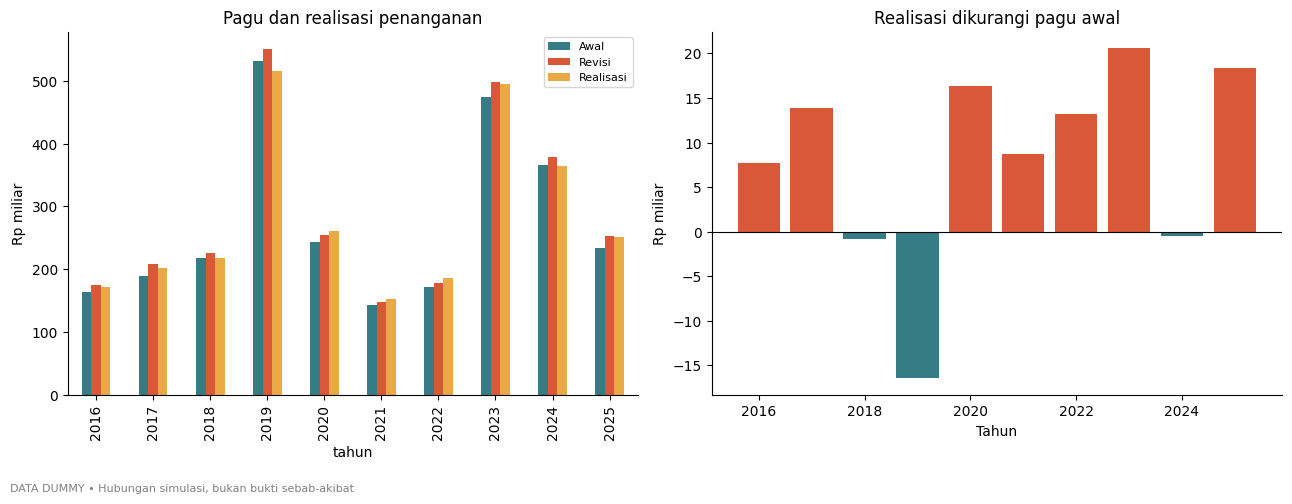

In [16]:
tahun=df.groupby("tahun").agg(kejadian=("id_kejadian","size"),anggaran_awal_rp=("anggaran_penanganan_awal_rp","sum"),anggaran_revisi_rp=("anggaran_penanganan_revisi_rp","sum"),realisasi_rp=("total_biaya_penanganan_rp","sum"),luas_ha=("luas_terbakar_ha","sum"),tepat_waktu_prop=("tepat_waktu","mean")).reset_index()
tahun["penyerapan_awal_pct"]=100*tahun.realisasi_rp/tahun.anggaran_awal_rp
tahun["selisih_awal_rp"]=tahun.realisasi_rp-tahun.anggaran_awal_rp
simpan(tahun,"anggaran_tahunan")
fig,ax=plt.subplots(1,2,figsize=(13,5))
t=tahun.set_index("tahun")[["anggaran_awal_rp","anggaran_revisi_rp","realisasi_rp"]]/1e9
t.plot.bar(ax=ax[0],color=WARNA[:3]);ax[0].set(title="Pagu dan realisasi penanganan",ylabel="Rp miliar");ax[0].legend(["Awal","Revisi","Realisasi"],fontsize=8)
ax[1].bar(tahun.tahun,tahun.selisih_awal_rp/1e9,color=[WARNA[1] if v>0 else WARNA[0] for v in tahun.selisih_awal_rp]);ax[1].axhline(0,color="black",lw=.8);ax[1].set(title="Realisasi dikurangi pagu awal",ylabel="Rp miliar",xlabel="Tahun")
grafik("01_anggaran_tahunan")

### 4. Komponen belanja dan wilayah
Identifikasi komponen yang menyumbang selisih terbesar. Selisih positif/negatif antarkejadian dapat saling menutupi sehingga total neto tidak cukup. Perbandingan provinsi tidak mengukur kinerja instansi: jumlah kejadian, akses, dan skala lahan berbeda.

**Cell 8**

 komponen   anggaran_rp  realisasi_rp  selisih_rp
Pemadaman 2160654284000 2237496363000 76842079000
 Logistik  461221185000  470283807000  9062622000
Kesehatan  114846794000  109910725000 -4936069000
Operasi udara Rp 144.15 miliar SUDAH TERMASUK pemadaman.
           provinsi  kejadian  anggaran_rp  realisasi_rp   luas_ha  median_biaya_per_ha  tepat_waktu_prop  penyerapan_pct  biaya_per_ha_tertimbang
  Kalimantan Tengah       145 515667336000  527726127000 57,085.09         8,358,648.74              0.60          102.34             9,244,552.77
               Riau       150 399885681000  404994411000 48,328.12         7,798,306.02              0.63          101.28             8,380,098.61
   Sumatera Selatan       136 319675211000  341354557000 43,179.95         7,700,697.69              0.60          106.78             7,905,394.91
     Sumatera Utara        32 310160164000  308979730000 28,173.01         5,683,092.90              0.62           99.62            10,967,224.66
   Kalim

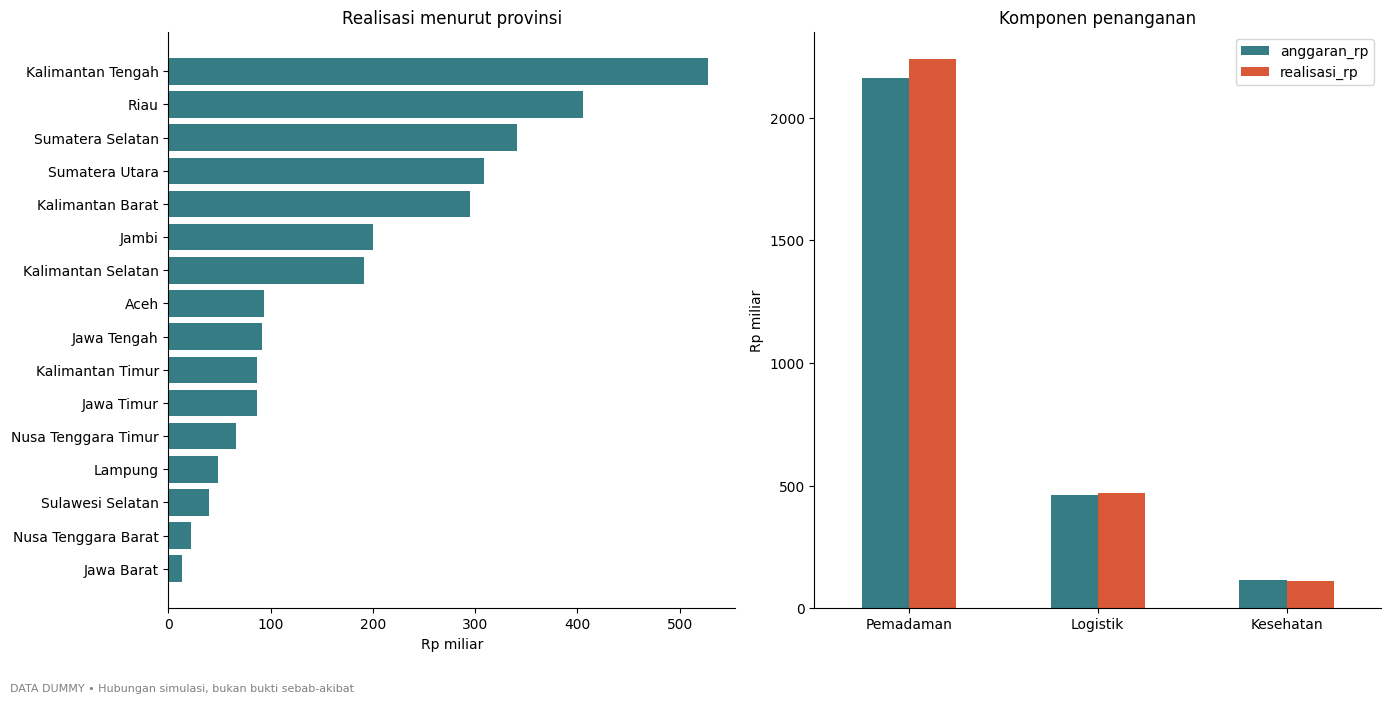

In [17]:
komponen=[]
for nama,a,b in [("Pemadaman","anggaran_pemadaman_rp","biaya_pemadaman_rp"),("Logistik","anggaran_logistik_rp","biaya_logistik_rp"),("Kesehatan","anggaran_kesehatan_rp","biaya_kesehatan_rp")]:
    komponen.append({"komponen":nama,"anggaran_rp":df[a].sum(),"realisasi_rp":df[b].sum(),"selisih_rp":df[b].sum()-df[a].sum()})
komponen=pd.DataFrame(komponen);simpan(komponen,"komponen_penanganan")
print(f"Operasi udara Rp {df.biaya_operasi_udara_rp.sum()/1e9:,.2f} miliar SUDAH TERMASUK pemadaman.")
wilayah=df.groupby("provinsi").agg(kejadian=("id_kejadian","size"),anggaran_rp=("anggaran_penanganan_awal_rp","sum"),realisasi_rp=("total_biaya_penanganan_rp","sum"),luas_ha=("luas_terbakar_ha","sum"),median_biaya_per_ha=("biaya_per_ha_rp","median"),tepat_waktu_prop=("tepat_waktu","mean")).reset_index()
wilayah["penyerapan_pct"]=100*wilayah.realisasi_rp/wilayah.anggaran_rp
wilayah["biaya_per_ha_tertimbang"]=wilayah.realisasi_rp/wilayah.luas_ha
simpan(wilayah.sort_values("realisasi_rp",ascending=False),"anggaran_provinsi")
fig,ax=plt.subplots(1,2,figsize=(14,7))
w=wilayah.sort_values("realisasi_rp");ax[0].barh(w.provinsi,w.realisasi_rp/1e9,color=WARNA[0]);ax[0].set(title="Realisasi menurut provinsi",xlabel="Rp miliar")
komponen.set_index("komponen")[["anggaran_rp","realisasi_rp"]].div(1e9).plot.bar(ax=ax[1],color=WARNA[:2]);ax[1].set(title="Komponen penanganan",ylabel="Rp miliar",xlabel="");ax[1].tick_params(axis="x",rotation=0)
grafik("02_wilayah_komponen")

### 5. Anggaran bersama hasil: jangan menilai efisiensi dari penyerapan saja
Empat kelompok menggabungkan batas anggaran awal dan target waktu. Label tidak menyatakan efisien/tidak efisien secara mutlak. Kelompok di bawah anggaran tetapi terlambat memerlukan pemeriksaan hasil, bukan langsung dinilai berhasil.

**Cell 9**

                status_kinerja  kejadian  realisasi_rp  median_biaya_per_ha_rp  median_luas_ha
   Dalam anggaran; tepat waktu       269  548431174000            6,696,097.17          112.87
     Dalam anggaran; terlambat       178  844286106000            6,881,577.41          210.47
Melebihi anggaran; tepat waktu       340  795490774000            7,150,136.03          117.66
  Melebihi anggaran; terlambat       213  629482841000            7,028,269.29          171.68


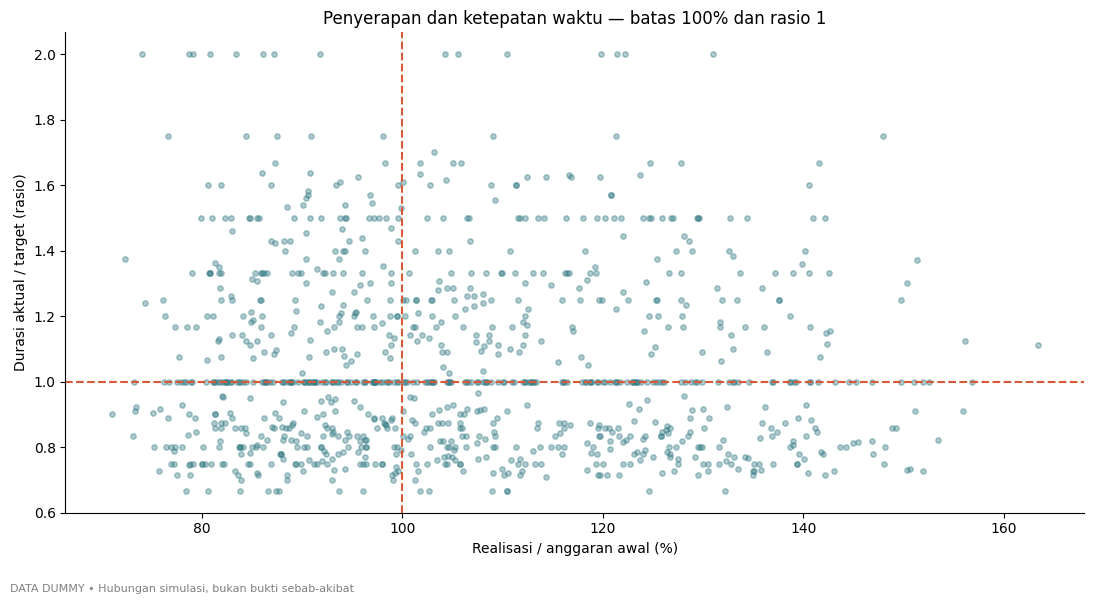

In [18]:
kinerja=df.groupby("status_kinerja").agg(kejadian=("id_kejadian","size"),realisasi_rp=("total_biaya_penanganan_rp","sum"),median_biaya_per_ha_rp=("biaya_per_ha_rp","median"),median_luas_ha=("luas_terbakar_ha","median")).reset_index()
simpan(kinerja,"kinerja_anggaran_waktu")
fig,ax=plt.subplots(figsize=(11,6))
ax.scatter(df.penyerapan_awal_pct,df.durasi_kebakaran_hari/df.target_pemadaman_hari,s=15,alpha=.4,color=WARNA[0]);ax.axvline(100,color=WARNA[1],ls="--");ax.axhline(1,color=WARNA[1],ls="--")
ax.set(xlabel="Realisasi / anggaran awal (%)",ylabel="Durasi aktual / target (rasio)",title="Penyerapan dan ketepatan waktu — batas 100% dan rasio 1")
grafik("03_anggaran_dan_waktu")

### 6. Pemulihan: realisasi dan luas yang dikerjakan
Evaluasi dilakukan 180 hari setelah padam. Bandingkan penyerapan pemulihan dengan progres luas. Progres lebih kecil daripada penyerapan hanya merupakan sinyal untuk pemeriksaan: pekerjaan punya biaya awal dan kompleksitas berbeda. Luas rehabilitasi awal tidak berarti ekosistem telah pulih.

**Cell 10**

jenis_tanah   anggaran_rp  realisasi_rp  target_ha  dikerjakan_ha  penyerapan_pct  progres_pct  biaya_per_ha_dikerjakan_rp
     Gambut 2908531132000 1853322802000 148,926.76      92,316.98           63.72        61.99               20,075,643.74
    Mineral 1697214290000 1018791599000 125,980.40      75,410.60           60.03        59.86               13,509,925.65


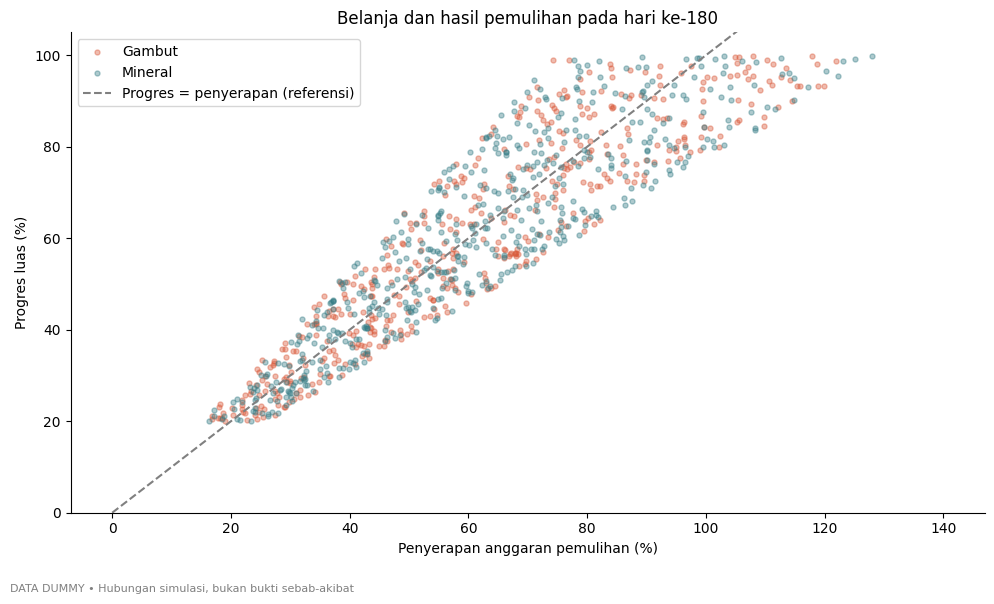

In [19]:
pulih=df.groupby("jenis_tanah").agg(anggaran_rp=("anggaran_pemulihan_rp","sum"),realisasi_rp=("realisasi_pemulihan_rp","sum"),target_ha=("luas_target_pemulihan_ha","sum"),dikerjakan_ha=("luas_dipulihkan_ha","sum")).reset_index()
pulih["penyerapan_pct"]=100*pulih.realisasi_rp/pulih.anggaran_rp
pulih["progres_pct"]=100*pulih.dikerjakan_ha/pulih.target_ha
pulih["biaya_per_ha_dikerjakan_rp"]=pulih.realisasi_rp/pulih.dikerjakan_ha
simpan(pulih,"pemulihan_hari180")
fig,ax=plt.subplots(figsize=(10,6))
for tanah,col in [("Gambut",WARNA[1]),("Mineral",WARNA[0])]:
    s=df[df.jenis_tanah.eq(tanah)];ax.scatter(s.penyerapan_pemulihan_pct,s.progres_pemulihan_pct,s=13,alpha=.4,label=tanah,color=col)
ax.plot([0,140],[0,140],ls="--",color="gray",label="Progres = penyerapan (referensi)");ax.set(xlabel="Penyerapan anggaran pemulihan (%)",ylabel="Progres luas (%)",title="Belanja dan hasil pemulihan pada hari ke-180",ylim=(0,105));ax.legend()
grafik("04_pemulihan")

### 7. Faktor-faktor yang berkaitan dengan biaya
Faktor operasional: akses, jarak pos, keterlambatan respons, sumber air, operasi udara, dan personel. Faktor kebakaran: luas, durasi, tanah/gambut, angin, dan hari tanpa hujan. Data generator sengaja menghubungkan faktor dengan biaya; temuan ini bukan bukti bahwa hubungan yang sama berlaku di dunia nyata.

Tampilkan jumlah sampel, median biaya/ha, serta rasio biaya/luas tertimbang. Operasi udara dipilih untuk sebagian kejadian besar: perbedaan biaya tidak boleh dianggap efek kausal operasi udara.

**Cell 11**


Faktor: akses_lokasi
akses_lokasi   n  median_luas_ha  median_biaya_per_ha_rp  median_biaya_per_ha_setara2016_rp  realisasi_rp    luas_ha   anggaran_rp  biaya_per_ha_tertimbang_rp  penyerapan_pct
       Mudah 344          140.95            5,646,680.64                       4,696,556.02  676055536000 109,626.33  686953047000                6,166,908.41           98.41
      Sedang 414          141.23            7,147,410.96                       5,909,442.59 1297920309000 154,089.89 1278546603000                8,423,137.36          101.52
       Sulit 242          122.34            8,677,408.87                       7,278,210.54  843715050000  90,478.78  771222613000                9,325,004.71          109.40

Faktor: jenis_tanah
jenis_tanah   n  median_luas_ha  median_biaya_per_ha_rp  median_biaya_per_ha_setara2016_rp  realisasi_rp    luas_ha   anggaran_rp  biaya_per_ha_tertimbang_rp  penyerapan_pct
     Gambut 477          159.58            8,953,496.37                       7,595

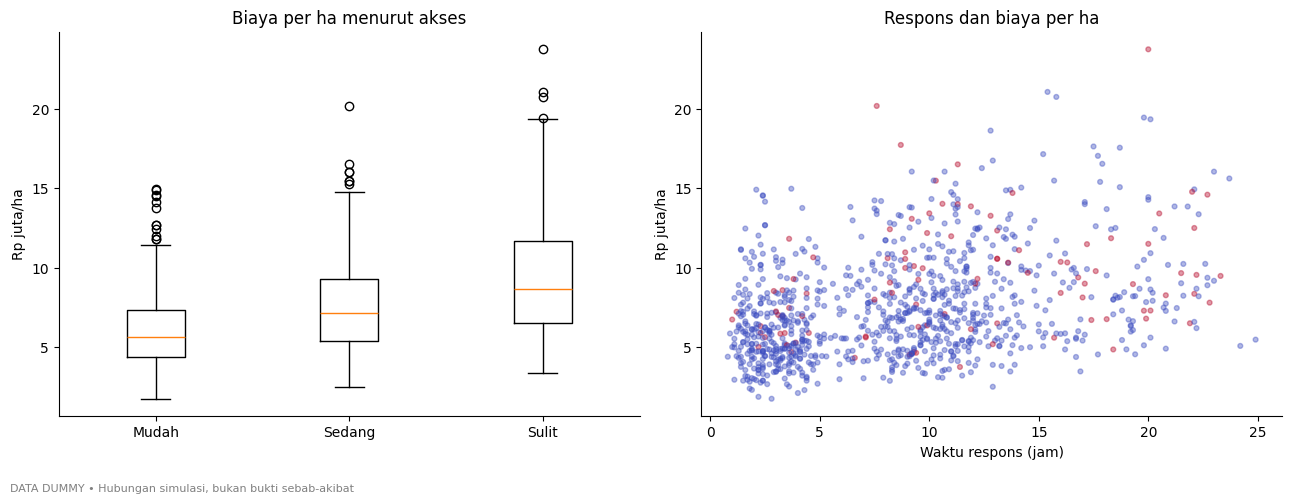

In [20]:
def ringkas_faktor(kolom):
    t=df.groupby(kolom,observed=True).agg(n=("id_kejadian","size"),median_luas_ha=("luas_terbakar_ha","median"),median_biaya_per_ha_rp=("biaya_per_ha_rp","median"),median_biaya_per_ha_setara2016_rp=("biaya_per_ha_setara2016_rp","median"),realisasi_rp=("total_biaya_penanganan_rp","sum"),luas_ha=("luas_terbakar_ha","sum"),anggaran_rp=("anggaran_penanganan_awal_rp","sum")).reset_index()
    t["biaya_per_ha_tertimbang_rp"]=t.realisasi_rp/t.luas_ha;t["penyerapan_pct"]=100*t.realisasi_rp/t.anggaran_rp
    simpan(t,"faktor_"+kolom);return t
df["kelompok_respons"]=pd.cut(df.waktu_respons_jam,[0,6,12,np.inf],labels=["<=6 jam",">6–12 jam",">12 jam"])
for col in ["akses_lokasi","jenis_tanah","water_bombing","kelompok_respons"]:
    print("\nFaktor:",col);ringkas_faktor(col)
fig,ax=plt.subplots(1,2,figsize=(13,5))
ax[0].boxplot([df.loc[df.akses_lokasi.eq(a),"biaya_per_ha_rp"]/1e6 for a in ["Mudah","Sedang","Sulit"]],);ax[0].set_xticks([1,2,3],["Mudah","Sedang","Sulit"]);ax[0].set(title="Biaya per ha menurut akses",ylabel="Rp juta/ha")
ax[1].scatter(df.waktu_respons_jam,df.biaya_per_ha_rp/1e6,c=df.water_bombing,cmap="coolwarm",alpha=.4,s=12);ax[1].set(title="Respons dan biaya per ha",xlabel="Waktu respons (jam)",ylabel="Rp juta/ha")
grafik("05_faktor_operasional")

### 8. Korelasi dan pembanding dengan skala serupa
Korelasi Spearman menunjukkan hubungan peringkat. Bandingkan biaya/ha juga dalam kelas luas × jenis tanah, sehingga sebagian perbedaan skala terlihat. Ini belum mengendalikan semua faktor; kelompok kecil bisa tidak stabil. Perubahan 4%/tahun hanya asumsi harga generator, bukan inflasi Indonesia.

**Cell 12**

                  variabel  luas_terbakar_ha  durasi_kebakaran_hari  waktu_respons_jam  jarak_pos_km  kecepatan_angin_kmh  hari_tanpa_hujan  jarak_sumber_air_km  personel_dikerahkan  total_biaya_penanganan_rp  biaya_per_ha_setara2016_rp
          luas_terbakar_ha              1.00                   0.82               0.01         -0.02                 0.01             -0.02                -0.02                 0.84                       0.95                        0.04
     durasi_kebakaran_hari              0.82                   1.00              -0.00         -0.01                -0.00             -0.05                -0.04                 0.70                       0.88                        0.34
         waktu_respons_jam              0.01                  -0.00               1.00          0.85                 0.00              0.03                 0.76                -0.03                       0.12                        0.36
              jarak_pos_km             -0.02        

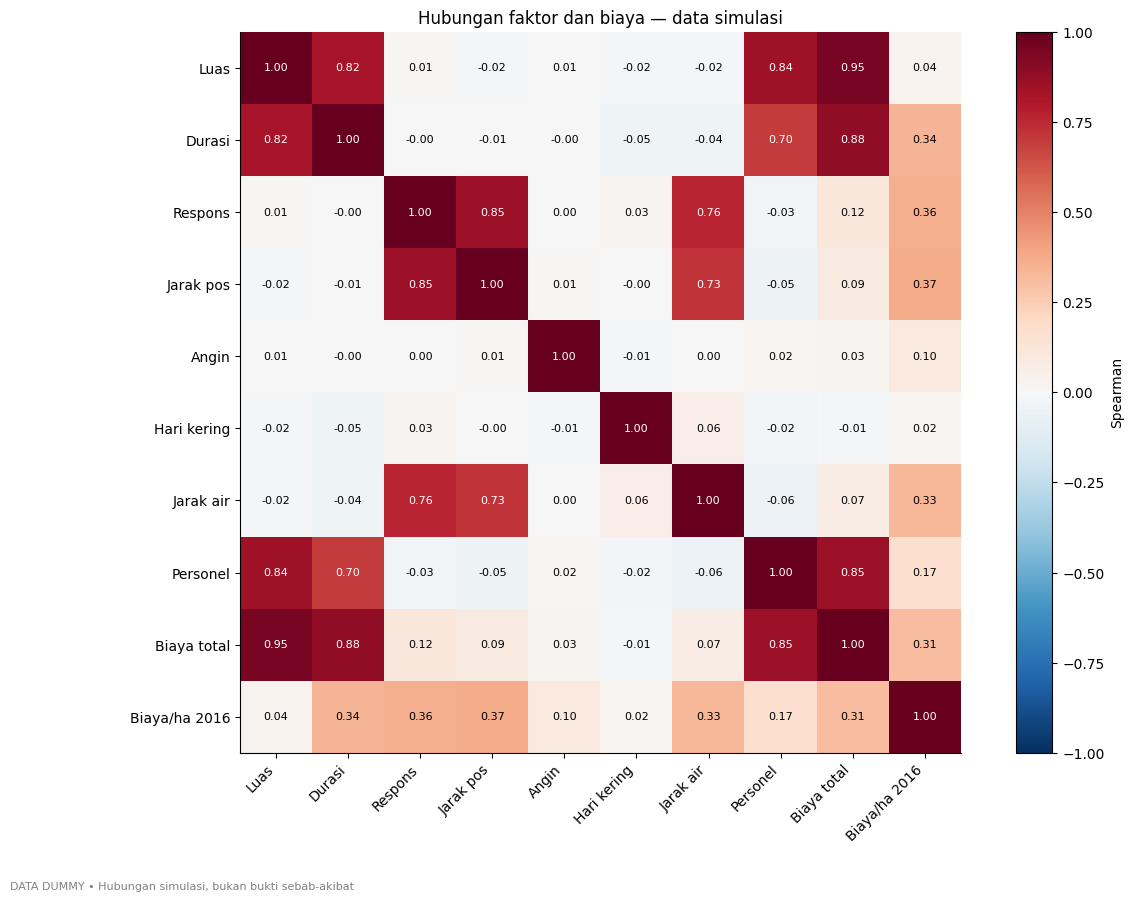

jenis_tanah tingkat_keparahan akses_lokasi  n  median_biaya_per_ha_setara2016_rp  sampel_kecil
     Gambut             Berat        Mudah 46                       6,342,620.68         False
     Gambut             Berat       Sedang 60                       8,126,986.64         False
     Gambut             Berat        Sulit 30                       8,991,057.96         False
     Gambut            Ringan        Mudah 31                       6,050,776.38         False
     Gambut            Ringan       Sedang 27                       8,569,239.39         False
     Gambut            Ringan        Sulit 27                      10,982,167.29         False
     Gambut      Sangat berat        Mudah 13                       5,033,278.25         False
     Gambut      Sangat berat       Sedang 16                       8,089,704.22         False
     Gambut      Sangat berat        Sulit  8                      10,402,326.26          True
     Gambut            Sedang        Mudah 76     

In [21]:
variabel=["luas_terbakar_ha","durasi_kebakaran_hari","waktu_respons_jam","jarak_pos_km","kecepatan_angin_kmh","hari_tanpa_hujan","jarak_sumber_air_km","personel_dikerahkan","total_biaya_penanganan_rp","biaya_per_ha_setara2016_rp"]
corr=df[variabel].corr(method="spearman")
simpan(corr.reset_index(names="variabel"),"korelasi_spearman")
fig,ax=plt.subplots(figsize=(12,9));im=ax.imshow(corr,vmin=-1,vmax=1,cmap="RdBu_r")
labels=["Luas","Durasi","Respons","Jarak pos","Angin","Hari kering","Jarak air","Personel","Biaya total","Biaya/ha 2016"]
ax.set_xticks(range(len(labels)),labels,rotation=45,ha="right");ax.set_yticks(range(len(labels)),labels)
for i in range(len(labels)):
    for j in range(len(labels)):ax.text(j,i,f"{corr.iloc[i,j]:.2f}",ha="center",va="center",fontsize=8,color="white" if abs(corr.iloc[i,j])>.6 else "black")
fig.colorbar(im,ax=ax,label="Spearman");ax.set_title("Hubungan faktor dan biaya — data simulasi");grafik("06_korelasi")
strata=df.groupby(["jenis_tanah","tingkat_keparahan","akses_lokasi"]).agg(n=("id_kejadian","size"),median_biaya_per_ha_setara2016_rp=("biaya_per_ha_setara2016_rp","median")).reset_index()
strata["sampel_kecil"]=strata.n<10
simpan(strata,"pembanding_tanah_luas_akses")

### 9. Kejadian yang memerlukan pemeriksaan anggaran
Peringkat pembengkakan nominal berbeda dengan persentase: kejadian kecil dapat memiliki persentase tinggi tetapi nominal rendah. Tidak menghapus kejadian ekstrem. Daftar ini untuk latihan pemeriksaan, bukan tuduhan penyimpangan.

**Cell 13**

In [22]:
kol=["id_kejadian","provinsi","luas_terbakar_ha","akses_lokasi","water_bombing","anggaran_penanganan_awal_rp","total_biaya_penanganan_rp","selisih_awal_rp","penyerapan_awal_pct","status_kinerja"]
simpan(df[df.selisih_awal_rp>0].nlargest(15,"selisih_awal_rp")[kol],"15_pembengkakan_nominal")
simpan(df.nlargest(15,"penyerapan_awal_pct")[kol],"15_penyerapan_tertinggi")
top=df.nlargest(100,"total_biaya_penanganan_rp")
print(f"10% kejadian berbiaya terbesar menyumbang {100*top.total_biaya_penanganan_rp.sum()/R:.2f}% realisasi penanganan.")

  id_kejadian          provinsi  luas_terbakar_ha akses_lokasi  water_bombing  anggaran_penanganan_awal_rp  total_biaya_penanganan_rp  selisih_awal_rp  penyerapan_awal_pct                 status_kinerja
KBR-2023-0077    Sumatera Utara          3,552.72        Sulit              1                  34947206000                52542146000      17594940000               150.35 Melebihi anggaran; tepat waktu
KBR-2022-0097       Jawa Tengah          9,219.62        Sulit              1                  49105730000                59918443000      10812713000               122.02 Melebihi anggaran; tepat waktu
KBR-2025-0038  Sumatera Selatan          3,445.60        Sulit              1                  20516767000                31001437000      10484670000               151.10 Melebihi anggaran; tepat waktu
KBR-2017-0041             Jambi          3,154.24       Sedang              1                  23988210000                33334548000       9346338000               138.96 Melebihi anggara

### 10. Skenario sensitivitas biaya
Skenario mengubah harga komponen tertentu dengan jumlah pekerjaan dan hasil tetap. Logistik ±10% dan harga operasi udara ±20% adalah asumsi pengguna, bukan proyeksi atau penghematan yang pasti. Pagu pembanding tetap anggaran awal. Komponen udara diganti hanya di dalam pemadaman agar tidak dihitung dua kali.

**Cell 14**

                    skenario         realisasi_rp       perubahan_rp  penyerapan_awal_pct  kejadian_melebihi_pagu
                       Dasar 2,817,690,895,000.00               0.00               102.96                     553
           Logistik naik 10% 2,864,719,275,700.00  47,028,380,700.00               104.68                     587
          Logistik turun 10% 2,770,662,514,300.00 -47,028,380,700.00               101.24                     526
        Tarif udara naik 20% 2,846,520,632,400.00  28,829,737,400.00               104.01                     557
       Tarif udara turun 20% 2,788,861,157,600.00 -28,829,737,400.00               101.91                     545
Logistik +10% dan udara +20% 2,893,549,013,100.00  75,858,118,100.00               105.73                     590


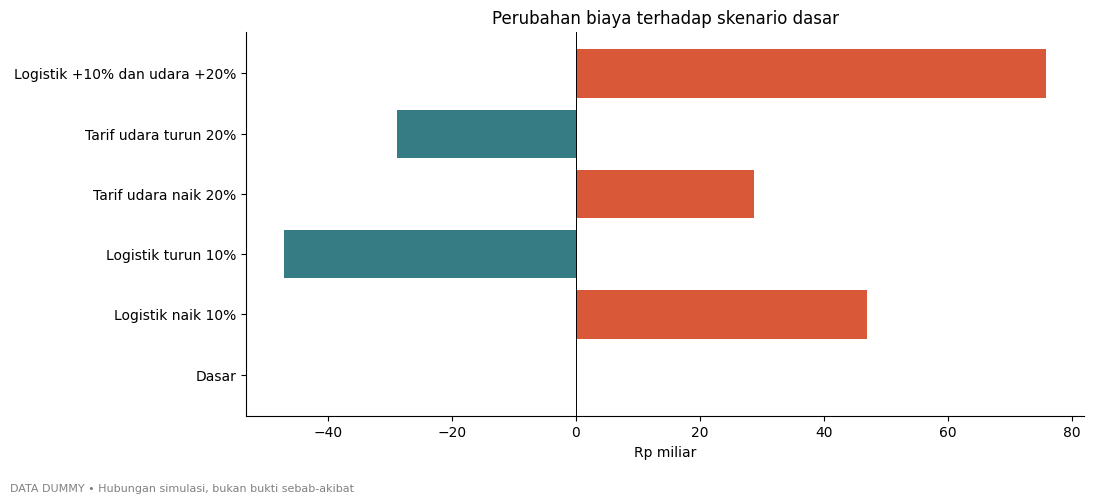

In [23]:
skenario=[]
for nama,logpct,airpct in [("Dasar",0,0),("Logistik naik 10%",.1,0),("Logistik turun 10%",-.1,0),("Tarif udara naik 20%",0,.2),("Tarif udara turun 20%",0,-.2),("Logistik +10% dan udara +20%",.1,.2)]:
    baru=df.total_biaya_penanganan_rp+df.biaya_logistik_rp*logpct+df.biaya_operasi_udara_rp*airpct
    skenario.append({"skenario":nama,"realisasi_rp":baru.sum(),"perubahan_rp":baru.sum()-R,"penyerapan_awal_pct":100*baru.sum()/B,"kejadian_melebihi_pagu":int((baru>df.anggaran_penanganan_awal_rp).sum())})
skenario=pd.DataFrame(skenario);simpan(skenario,"sensitivitas_anggaran")
fig,ax=plt.subplots(figsize=(11,5));ax.barh(skenario.skenario,skenario.perubahan_rp/1e9,color=[WARNA[1] if v>0 else WARNA[0] for v in skenario.perubahan_rp]);ax.axvline(0,color="black",lw=.7);ax.set(title="Perubahan biaya terhadap skenario dasar",xlabel="Rp miliar");grafik("07_sensitivitas")

### 11. Konteks tujuan, pihak, dan orang yang terlibat
Tujuan pembakaran berbeda dengan jenis lahan. Untuk kelalaian, tidak ada luas yang sengaja ditargetkan. NULL tidak diganti nol. Jumlah pelaksana per kejadian bukan orang unik dan terpisah dari petugas serta warga terdampak.

Luas pada rekap pihak berarti **luas kejadian yang terkait**, bukan luas yang dapat diatribusikan kepada pihak tersebut. Satu kejadian dapat terkait beberapa pihak: JANGAN menjumlahkan rekap pihak sebagai total lahan atau total biaya. Tidak ada nama orang/perusahaan nyata.

**Cell 15**

In [24]:
tujuan=df.groupby("tujuan_pembakaran").agg(kejadian=("id_kejadian","size"),luas_aktual_ha=("luas_terbakar_ha","sum"),realisasi_penanganan_rp=("total_biaya_penanganan_rp","sum"),median_biaya_per_ha=("biaya_per_ha_rp","median")).reset_index()
simpan(tujuan,"konteks_tujuan")
sengaja=df[df.luas_target_pembakaran_ha.notna()].copy()
sengaja["luas_di_luar_target_ha"]=sengaja.luas_terbakar_ha-sengaja.luas_target_pembakaran_ha
simpan(sengaja.groupby("tujuan_pembakaran").agg(kejadian=("id_kejadian","size"),target_ha=("luas_target_pembakaran_ha","sum"),aktual_ha=("luas_terbakar_ha","sum"),di_luar_target_ha=("luas_di_luar_target_ha","sum")).reset_index(),"luas_target_dan_aktual")
# Unique event-party pairs avoid duplicate roles for the same party within one event.
hub=relasi[["id_kejadian","kode_pihak"]].drop_duplicates().merge(pihak,on="kode_pihak",validate="many_to_one").merge(df[["id_kejadian","luas_terbakar_ha","total_biaya_penanganan_rp"]],on="id_kejadian",validate="many_to_one")
rekap=hub.groupby(["kode_pihak","nama_pihak_fiktif","kategori_pihak"]).agg(kejadian_terkait=("id_kejadian","nunique"),luas_kejadian_terkait_ha=("luas_terbakar_ha","sum"),biaya_kejadian_terkait_rp=("total_biaya_penanganan_rp","sum")).reset_index()
rekap.to_csv(HASIL/"pihak_luas_terkait_tidak_aditif.csv",index=False,encoding="utf-8-sig")
print(rekap.nlargest(10,"luas_kejadian_terkait_ha").to_string(index=False))
print("Jumlah kejadian dengan jumlah pelaksana diketahui:",df.jumlah_pelaksana_pembakaran.notna().sum())
print("Akumulasi catatan pelaksana pada kejadian yang diketahui:",int(df.jumlah_pelaksana_pembakaran.sum()),"(BUKAN orang unik)")
print("Pihak fiktif aktif:",hub.kode_pihak.nunique(),"(entitas, BUKAN jumlah orang)")

                            tujuan_pembakaran  kejadian  luas_aktual_ha  realisasi_penanganan_rp  median_biaya_per_ha
                              Belum diketahui       153       46,885.07             389059641000         7,432,644.63
                       Pembersihan sisa panen       134       50,465.80             362333661000         7,086,609.51
                     Pembukaan kebun campuran       151       73,782.20             729230711000         6,626,411.75
                        Pembukaan kebun sawit       132       37,770.84             257186968000         6,521,121.71
                   Pembukaan pertanian pangan       147       57,091.18             433868923000         6,717,589.34
Tidak ada tujuan pembakaran lahan (kelalaian)       283       88,199.91             646010991000         7,028,269.29
         tujuan_pembakaran  kejadian  target_ha  aktual_ha  di_luar_target_ha
    Pembersihan sisa panen       134  33,002.70  50,465.80          17,463.10
  Pembukaan kebun 

### 12. Kesimpulan, batasan, dan tindak lanjut
Kesimpulan dihitung dari data versi 2. Untuk penilaian nyata perlu bukti pengadaan, harga satuan, keluaran yang diverifikasi, tingkat kesulitan, dan standar layanan. Analisis ini tidak mengidentifikasi korupsi atau sebab-akibat dan tidak meramalkan biaya nasional.

**Cell 16**

In [25]:
over=(df.selisih_awal_rp>0).sum()
both=(df.sesuai_anggaran_awal & df.tepat_waktu).sum()
uraian=f"""RINGKASAN ANALISIS ANGGARAN — SELURUH DATA DUMMY
1. Jumlah kejadian: {len(df):,}; periode {df.tahun.min()}–{df.tahun.max()}; {df.provinsi.nunique()} provinsi terpilih.
2. Anggaran awal respons Rp {B/1e9:,.2f} miliar; revisi Rp {V/1e9:,.2f} miliar; realisasi Rp {R/1e9:,.2f} miliar.
3. Penyerapan terhadap awal {100*R/B:.2f}%; terhadap revisi {100*R/V:.2f}%.
4. {over} kejadian melampaui pagu awal; {int((df.selisih_revisi_rp>0).sum())} melampaui pagu revisi.
5. {both} kejadian berada dalam anggaran awal sekaligus tepat waktu. Ini indikator gabungan, bukan vonis efisiensi.
6. Biaya respons/ha tertimbang Rp {R/df.luas_terbakar_ha.sum():,.0f}; median kejadian Rp {df.biaya_per_ha_rp.median():,.0f}.
7. Pemulihan: anggaran Rp {df.anggaran_pemulihan_rp.sum()/1e9:,.2f} miliar; realisasi Rp {df.realisasi_pemulihan_rp.sum()/1e9:,.2f} miliar.
8. Pada hari ke-180, progres luas pemulihan tertimbang {100*df.luas_dipulihkan_ha.sum()/df.luas_target_pemulihan_ha.sum():.2f}%.
9. Anggaran gabungan awal Rp {df.total_anggaran_awal_gabungan_rp.sum()/1e9:,.2f} miliar; realisasi gabungan Rp {df.total_realisasi_gabungan_rp.sum()/1e9:,.2f} miliar.

Tindak lanjut latihan:
- Periksa pembengkakan nominal besar, pagu awal vs revisi, dan alasan keterlambatan bersama-sama.
- Bandingkan biaya per hektare pada kelas luas, tanah, dan akses yang serupa; perhatikan jumlah sampel.
- Audit komponen pemadaman/logistik yang dominan; operasi udara jangan dihitung dua kali.
- Evaluasi pemulihan dengan keluaran fisik dan realisasi, bukan hanya persentase penyerapan.
- Gunakan skenario harga untuk cadangan anggaran; jangan mengklaim penghematan tanpa menjaga hasil.

BATASAN: semua faktor dan pihak fiktif; bobot dan hubungan biaya dibuat oleh generator.
NULL berarti tidak berlaku/belum diketahui. Akumulasi orang bukan orang unik.
Korelasi tidak membuktikan kausalitas. Penyerapan rendah tidak otomatis efisien.
"""
print(uraian);(HASIL/"kesimpulan_anggaran.txt").write_text(uraian,encoding="utf-8")
df.to_csv(HASIL/"data_analisis_anggaran.csv",index=False,encoding="utf-8-sig")
meta.to_csv(HASIL/"metadata.csv",index=False,encoding="utf-8-sig")
kamus.to_csv(HASIL/"kamus_faktor.csv",index=False,encoding="utf-8-sig")

RINGKASAN ANALISIS ANGGARAN — SELURUH DATA DUMMY
1. Jumlah kejadian: 1,000; periode 2016–2025; 16 provinsi terpilih.
2. Anggaran awal respons Rp 2,736.72 miliar; revisi Rp 2,873.50 miliar; realisasi Rp 2,817.69 miliar.
3. Penyerapan terhadap awal 102.96%; terhadap revisi 98.06%.
4. 553 kejadian melampaui pagu awal; 442 melampaui pagu revisi.
5. 269 kejadian berada dalam anggaran awal sekaligus tepat waktu. Ini indikator gabungan, bukan vonis efisiensi.
6. Biaya respons/ha tertimbang Rp 7,955,197; median kejadian Rp 6,929,541.
7. Pemulihan: anggaran Rp 4,605.75 miliar; realisasi Rp 2,872.11 miliar.
8. Pada hari ke-180, progres luas pemulihan tertimbang 61.01%.
9. Anggaran gabungan awal Rp 7,342.47 miliar; realisasi gabungan Rp 5,689.81 miliar.

Tindak lanjut latihan:
- Periksa pembengkakan nominal besar, pagu awal vs revisi, dan alasan keterlambatan bersama-sama.
- Bandingkan biaya per hektare pada kelas luas, tanah, dan akses yang serupa; perhatikan jumlah sampel.
- Audit komponen pema

**Unduh hasil analisis (opsional)**
Jalankan setelah analisis selesai untuk menyimpan seluruh tabel CSV, grafik, dan kesimpulan dari folder hasil ke laptop.

**Cell 17**

In [26]:
import shutil
from google.colab import files

arsip = shutil.make_archive("Hasil_Analisis_Anggaran", "zip", HASIL)
files.download(arsip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
import pandas as pd
from google.colab import files

nama_file = "Analisis_Anggaran.xlsx"
akses = pd.read_csv("hasil/faktor_akses_lokasi.csv")

with pd.ExcelWriter(nama_file, engine="openpyxl") as excel:
    ringkas.to_excel(excel, sheet_name="Ringkasan", index=False)
    akses.to_excel(excel, sheet_name="Akses lokasi", index=False)

files.download(nama_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>